## Pre-Processing

In [2]:
!pip install -q kagglehub

import kagglehub
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print(path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
/kaggle/input/brain-tumor-mri-dataset


In [3]:
import os

print(os.listdir(path))

['Training', 'Testing']


In [4]:
training_path = os.path.join(path, "Training")
testing_path = os.path.join(path, "Testing")

print("Training classes:")
print(os.listdir(training_path))

print("\nTesting classes:")
print(os.listdir(testing_path))

Training classes:
['pituitary', 'notumor', 'meningioma', 'glioma']

Testing classes:
['pituitary', 'notumor', 'meningioma', 'glioma']


In [5]:
for class_name in os.listdir(training_path):
    class_path = os.path.join(training_path, class_name)

    if os.path.isdir(class_path):
        print(class_name, len(os.listdir(class_path)))

pituitary 1400
notumor 1400
meningioma 1400
glioma 1400


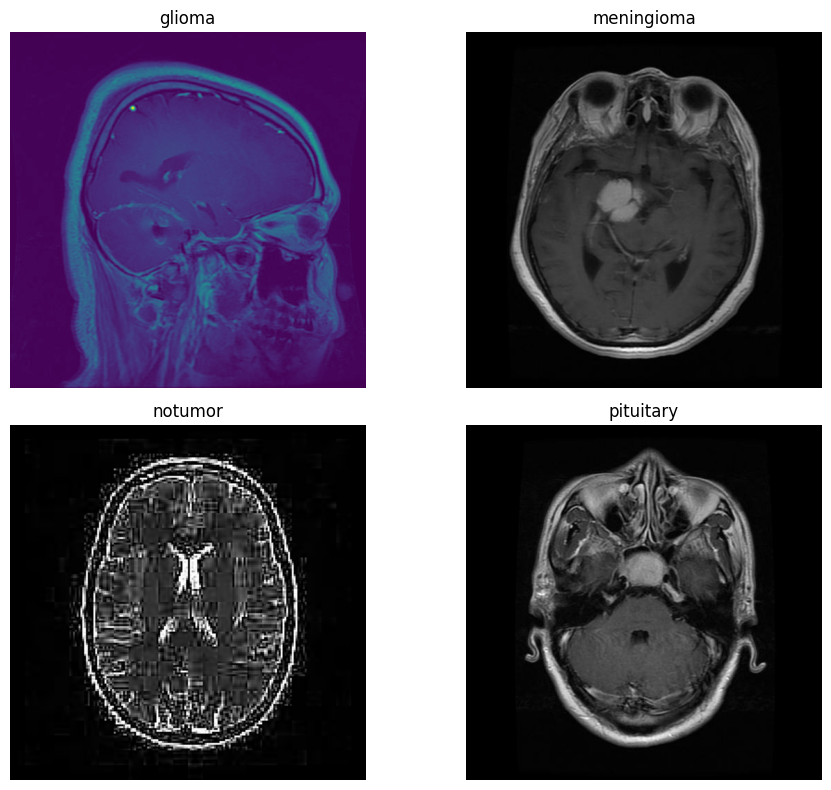

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

class_names = sorted(os.listdir(training_path))

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(class_names):
    class_path = os.path.join(training_path, class_name)
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
for class_name in os.listdir(testing_path):
    class_path = os.path.join(testing_path, class_name)

    if os.path.isdir(class_path):
        print(class_name, len(os.listdir(class_path)))

pituitary 400
notumor 400
meningioma 400
glioma 400


In [8]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [9]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    training_path,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    training_path,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.


In [10]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    testing_path,
    shuffle=False,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 1600 files belonging to 4 classes.


In [11]:
class_names = train_ds.class_names
print(class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [12]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 10 labels: [0 2 3 1 3 2 1 1 0 2]


# Experiments


## Exp. 1

In [13]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [14]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

inputs = layers.Input(shape=(224, 224, 3))

x = preprocess_input(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.2)(x)

outputs = layers.Dense(4, activation="softmax")(x)

model = models.Model(inputs, outputs)

In [15]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 190ms/step - accuracy: 0.7353 - loss: 0.6819 - val_accuracy: 0.8759 - val_loss: 0.3554
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.8583 - loss: 0.3913 - val_accuracy: 0.8911 - val_loss: 0.3093
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - accuracy: 0.8730 - loss: 0.3266 - val_accuracy: 0.9116 - val_loss: 0.2533
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8980 - loss: 0.2869 - val_accuracy: 0.9134 - val_loss: 0.2541
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.8962 - loss: 0.2706 - val_accuracy: 0.9170 - val_loss: 0.2232
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 81ms/step - accuracy: 0.9161 - loss: 0.2391 - val_accuracy: 0.9223 - val_loss: 0.2214
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9165 - loss: 0.2218 - val_accuracy: 0.9304 - val_loss: 0.1974
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 83ms/step - accuracy: 0.9243 - loss: 0.2097 -

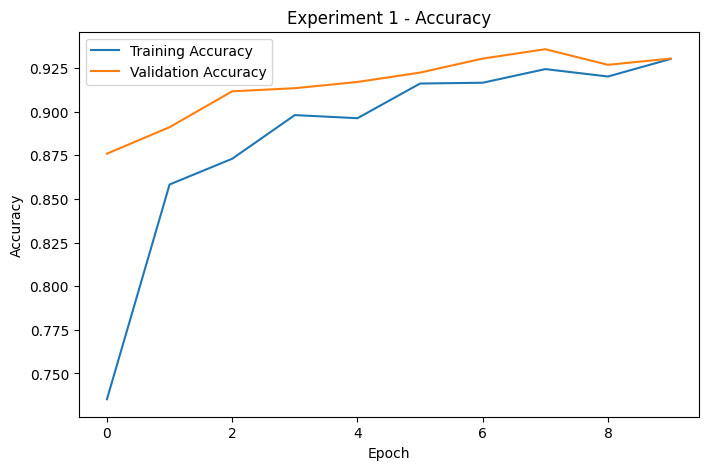

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history_1.history["accuracy"], label="Training Accuracy")
plt.plot(history_1.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Experiment 1 - Accuracy")
plt.legend()
plt.show()

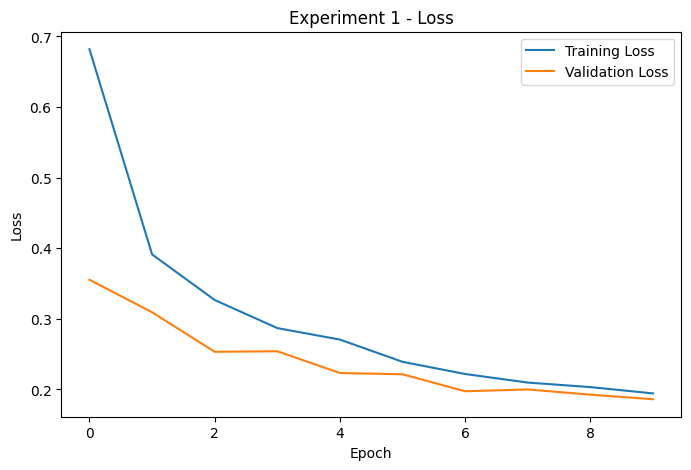

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history_1.history["loss"], label="Training Loss")
plt.plot(history_1.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Experiment 1 - Loss")
plt.legend()
plt.show()

## Exp. 2

In [20]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
])

In [21]:
base_model_2 = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_2.trainable = False

inputs = tf.keras.layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = preprocess_input(x)

x = base_model_2(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(4, activation="softmax")(x)

model_2 = tf.keras.Model(inputs, outputs)

In [22]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
history_2 = model_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - accuracy: 0.7377 - loss: 0.6618 - val_accuracy: 0.8196 - val_loss: 0.4548
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - accuracy: 0.8442 - loss: 0.4104 - val_accuracy: 0.8545 - val_loss: 0.3806
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - accuracy: 0.8627 - loss: 0.3572 - val_accuracy: 0.8696 - val_loss: 0.3504
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8672 - loss: 0.3450 - val_accuracy: 0.8625 - val_loss: 0.3857
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - accuracy: 0.8924 - loss: 0.2993 - val_accuracy: 0.8741 - val_loss: 0.3571
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8859 - loss: 0.2977 - val_accuracy: 0.8839 - val_loss: 0.3333
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8900 - loss: 0.2784 - val_accuracy: 0.8955 - val_loss: 0.2963
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8975 - loss: 0.2691 - 

## Exp. 3

In [24]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

base_model_3 = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_3.trainable = False

In [25]:
inputs = tf.keras.layers.Input(shape=(224, 224, 3))

x = preprocess_input(inputs)
x = base_model_3(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(4, activation="softmax")(x)

model_3 = tf.keras.Model(inputs, outputs)

In [26]:
model_3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
history_3 = model_3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 149ms/step - accuracy: 0.4346 - loss: 1.2524 - val_accuracy: 0.6732 - val_loss: 0.8773
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 85ms/step - accuracy: 0.6538 - loss: 0.8602 - val_accuracy: 0.7777 - val_loss: 0.6603
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.7277 - loss: 0.7092 - val_accuracy: 0.8241 - val_loss: 0.5576
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.7679 - loss: 0.6201 - val_accuracy: 0.8518 - val_loss: 0.4921
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.7929 - loss: 0.5669 - val_accuracy: 0.8625 - val_loss: 0.4495
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 82ms/step - accuracy: 0.8089 - loss: 0.5208 - val_accuracy: 0.8696 - val_loss: 0.4199
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.8201 - loss: 0.4947 - val_accuracy: 0.8723 - val_loss: 0.3926
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.8299 - loss: 0.4641 -

## Exp. 4

In [28]:
base_model_4 = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_4.trainable = False

inputs = tf.keras.layers.Input(shape=(224, 224, 3))

x = preprocess_input(inputs)
x = base_model_4(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.4)(x)

outputs = tf.keras.layers.Dense(4, activation="softmax")(x)

model_4 = tf.keras.Model(inputs, outputs)

In [29]:
model_4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
history_4 = model_4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 149ms/step - accuracy: 0.7105 - loss: 0.7541 - val_accuracy: 0.8696 - val_loss: 0.3661
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8292 - loss: 0.4547 - val_accuracy: 0.9080 - val_loss: 0.2919
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.8672 - loss: 0.3657 - val_accuracy: 0.9116 - val_loss: 0.2624
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8634 - loss: 0.3500 - val_accuracy: 0.9170 - val_loss: 0.2524
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 83ms/step - accuracy: 0.8766 - loss: 0.3195 - val_accuracy: 0.9116 - val_loss: 0.2420
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.8891 - loss: 0.2980 - val_accuracy: 0.9205 - val_loss: 0.2232
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 82ms/step - accuracy: 0.8967 - loss: 0.2766 - val_accuracy: 0.9205 - val_loss: 0.2295
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.8949 - loss: 0.2791 -

## Exp. 5

In [32]:
model.save_weights("experiment1.weights.h5")

In [33]:
base_model.trainable = True

print("Number of MobileNetV2 layers:", len(base_model.layers))

Number of MobileNetV2 layers: 154


In [34]:
fine_tune_at = len(base_model.layers) - 20

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

In [35]:
for layer in base_model.layers[fine_tune_at:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [36]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [37]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 1,200,004 (4.58 MB)

 Non-trainable params: 1,063,104 (4.06 MB)

In [38]:
history_5 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 114ms/step - accuracy: 0.9315 - loss: 0.1780 - val_accuracy: 0.9375 - val_loss: 0.1661
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.9482 - loss: 0.1434 - val_accuracy: 0.9455 - val_loss: 0.1544
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.9560 - loss: 0.1223 - val_accuracy: 0.9527 - val_loss: 0.1401
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accuracy: 0.9629 - loss: 0.1018 - val_accuracy: 0.9563 - val_loss: 0.1373
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9730 - loss: 0.0842 - val_accuracy: 0.9563 - val_loss: 0.1254


## Exp. 6

In [39]:
base_model_6 = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_6.trainable = False

inputs = tf.keras.layers.Input(shape=(224, 224, 3))

x = preprocess_input(inputs)
x = base_model_6(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(4, activation="softmax")(x)

model_6 = tf.keras.Model(inputs, outputs)

In [40]:
model_6.load_weights("experiment1.weights.h5")

In [41]:
base_model_6.trainable = True

fine_tune_at_6 = len(base_model_6.layers) - 40

for layer in base_model_6.layers[:fine_tune_at_6]:
    layer.trainable = False

for layer in base_model_6.layers[fine_tune_at_6:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [42]:
model_6.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [43]:
history_6 = model_6.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - accuracy: 0.9266 - loss: 0.1865 - val_accuracy: 0.9446 - val_loss: 0.1682
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 82ms/step - accuracy: 0.9529 - loss: 0.1329 - val_accuracy: 0.9545 - val_loss: 0.1432
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.9598 - loss: 0.1111 - val_accuracy: 0.9563 - val_loss: 0.1213
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 87ms/step - accuracy: 0.9754 - loss: 0.0770 - val_accuracy: 0.9554 - val_loss: 0.1230
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.9777 - loss: 0.0729 - val_accuracy: 0.9554 - val_loss: 0.1166


# Results

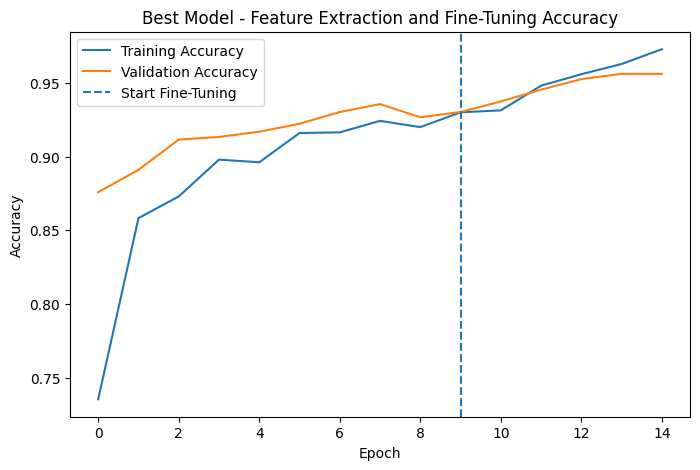

In [44]:
feature_acc = history_1.history["accuracy"]
feature_val_acc = history_1.history["val_accuracy"]

fine_acc = history_5.history["accuracy"]
fine_val_acc = history_5.history["val_accuracy"]

all_acc = feature_acc + fine_acc
all_val_acc = feature_val_acc + fine_val_acc

plt.figure(figsize=(8, 5))
plt.plot(all_acc, label="Training Accuracy")
plt.plot(all_val_acc, label="Validation Accuracy")
plt.axvline(x=9, linestyle="--", label="Start Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Best Model - Feature Extraction and Fine-Tuning Accuracy")
plt.legend()
plt.show()

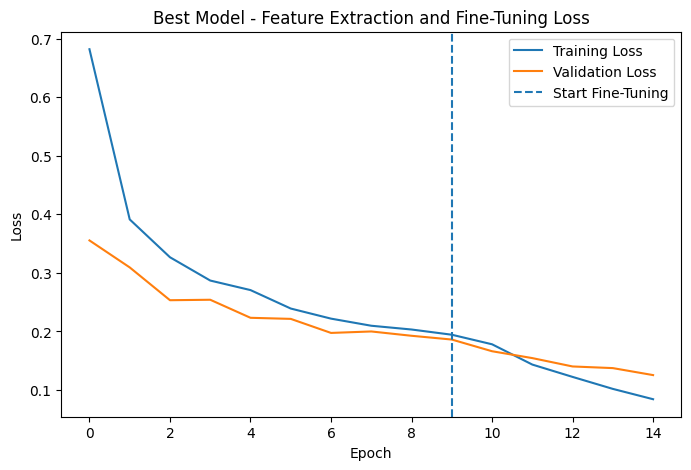

In [45]:
feature_loss = history_1.history["loss"]
feature_val_loss = history_1.history["val_loss"]

fine_loss = history_5.history["loss"]
fine_val_loss = history_5.history["val_loss"]

all_loss = feature_loss + fine_loss
all_val_loss = feature_val_loss + fine_val_loss

plt.figure(figsize=(8, 5))
plt.plot(all_loss, label="Training Loss")
plt.plot(all_val_loss, label="Validation Loss")
plt.axvline(x=9, linestyle="--", label="Start Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Best Model - Feature Extraction and Fine-Tuning Loss")
plt.legend()
plt.show()

In [46]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Final Test Accuracy:", test_accuracy)
print("Final Test Loss:", test_loss)

50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 138ms/step - accuracy: 0.9031 - loss: 0.4511
Final Test Accuracy: 0.903124988079071
Final Test Loss: 0.45106086134910583


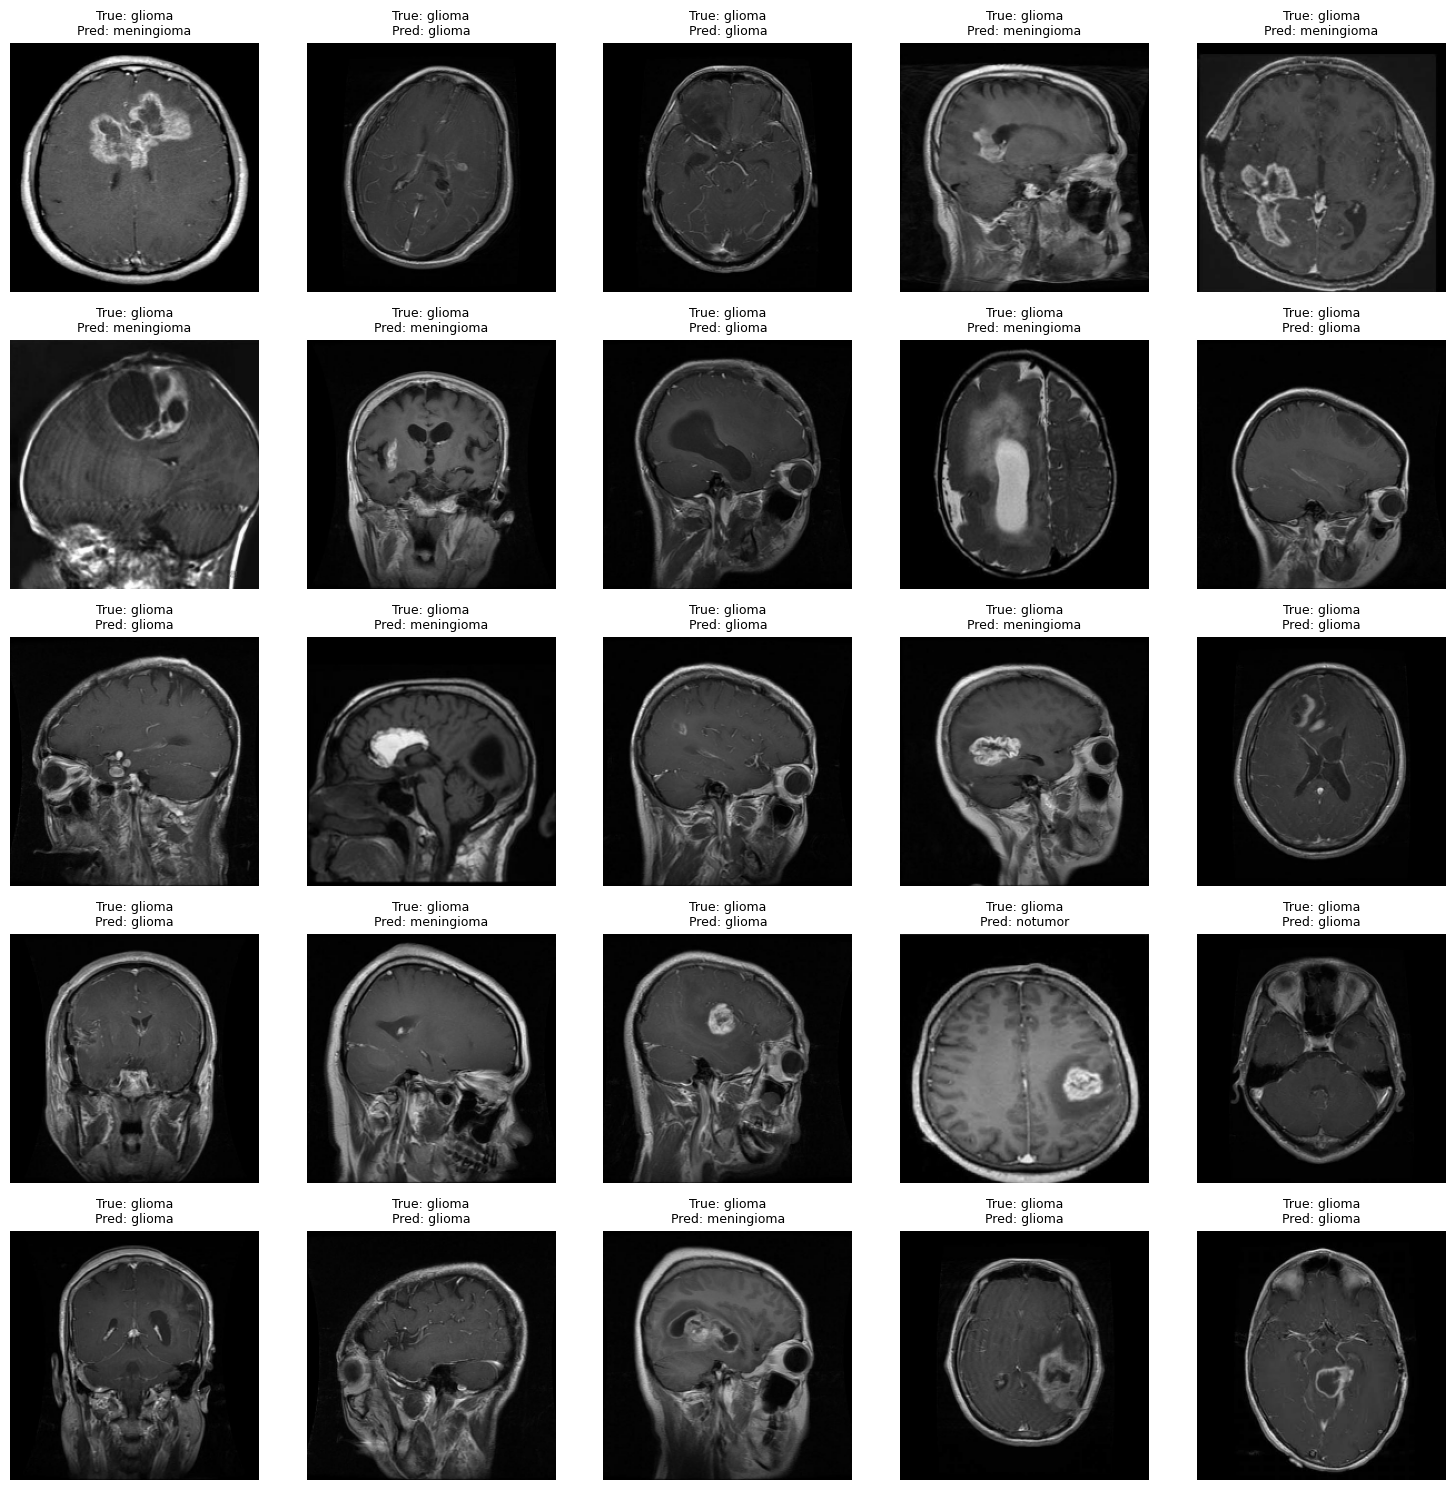

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# Take one batch from the test dataset
for images, labels in test_ds.take(1):
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    plt.figure(figsize=(15, 15))

    for i in range(25):
        plt.subplot(5, 5, i + 1)

        image = images[i].numpy().astype("uint8")
        plt.imshow(image)

        true_name = class_names[labels[i].numpy()]
        predicted_name = class_names[predicted_labels[i]]

        plt.title(
            f"True: {true_name}\nPred: {predicted_name}",
            fontsize=9
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [48]:
np.argmax(predictions, axis=1)

array([1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 2, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0])

In [49]:
sample_ds = tf.keras.utils.image_dataset_from_directory(
    testing_path,
    shuffle=True,
    seed=42,
    image_size=IMG_SIZE,
    batch_size=25
)

Found 1600 files belonging to 4 classes.


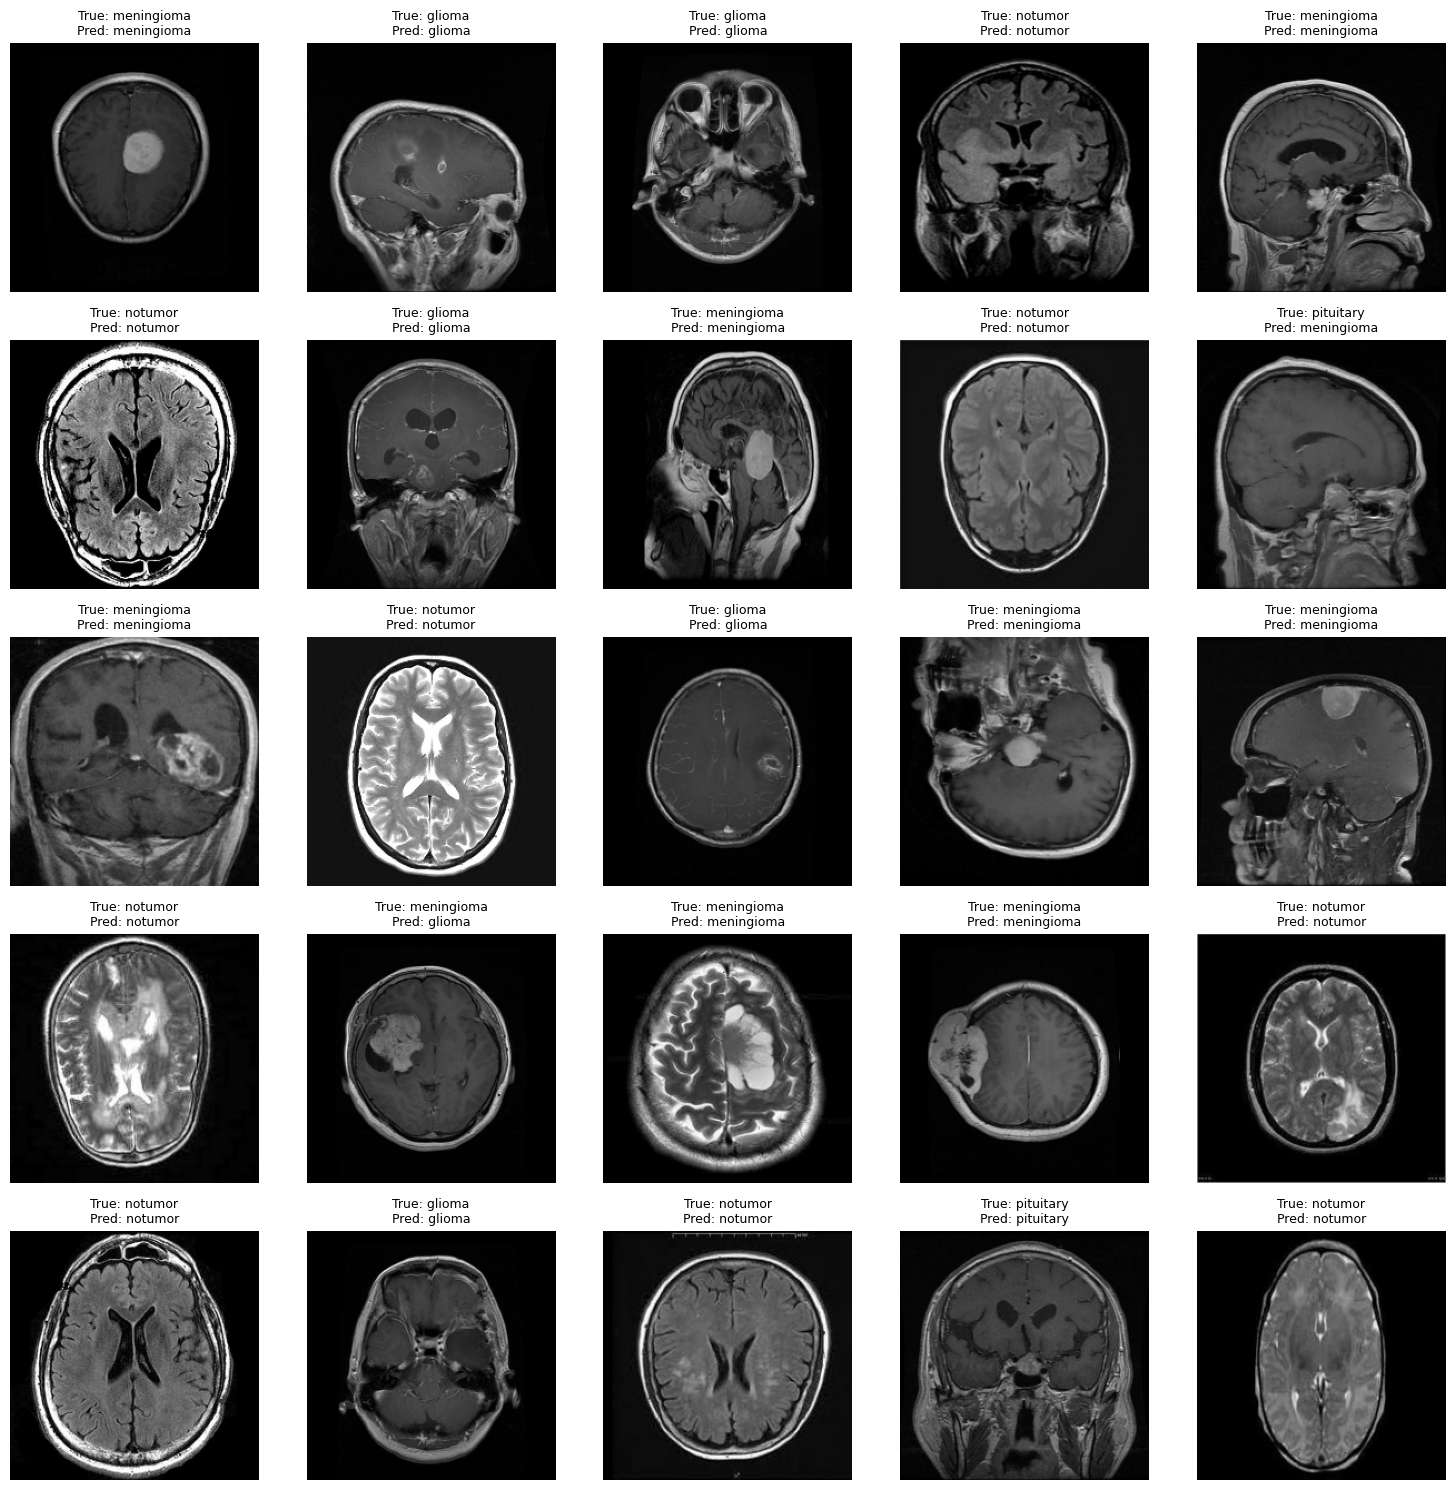

In [50]:
for images, labels in sample_ds.take(1):
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    plt.figure(figsize=(15, 15))

    for i in range(25):
        plt.subplot(5, 5, i + 1)

        image = images[i].numpy().astype("uint8")
        plt.imshow(image)

        true_name = class_names[labels[i].numpy()]
        predicted_name = class_names[predicted_labels[i]]

        plt.title(
            f"True: {true_name}\nPred: {predicted_name}",
            fontsize=9
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()